# Introduction

Code copied from:
https://github.com/zcakhaa/DeepLOB-Deep-Convolutional-Neural-Networks-for-Limit-Order-Books/blob/master/jupyter_pytorch/run_train_pytorch.ipynb


The shape of input $X = (X_1, X_2, ..., X_N)$ is $100 \times 40 \times N$, each input $X_i$ is a $100 \times 40$ matrix, where 40 is the order book:

$$\left( p_a^{(1)}(t), v_a^{(1)}(t), p_b^{(1)}(t), v_b^{(1)}(t),  p_a^{(2)}(t), v_a^{(2)}(t), p_b^{(2)}(t), v_b^{(2)}(t), ...,  p_a^{(10)}(t), v_a^{(10)}(t), p_b^{(10)}(t), v_b^{(10)}(t)\right)$$

And we take 100 events on order book to get the time changing features. So $X_i$ with current time index $t_i$ is $100 \times 1$: 

\begin{bmatrix}
p_a^{(1)}(t_i) & v_a^{(1)}(t_i) & p_b^{(1)}(t_i) & v_b^{(1)}(t_i)  & ... &  p_a^{(10)}(t_i) & v_a^{(10)}(t_i) & p_b^{(10)}(t_i) & v_b^{(10)}(t_i) \\
p_a^{(1)}(t_{i-1}) & v_a^{(1)}(t_{i-1}) & p_b^{(1)}(t_{i-1}) & v_b^{(1)}(t_{i-1}) &  ... &  p_a^{(10)}(t_{i-1}) & v_a^{(10)}(t_{i-1}) & p_b^{(10)}(t_{i-1}) & v_b^{(10)}(t_{i-1})  \\
...
\\
p_a^{(1)}(t_{i-99}) & v_a^{(1)}(t_{i-99}) & p_b^{(1)}(t_{i-99}) & v_b^{(1)}(t_{i-99}) &  ... &  p_a^{(10)}(t_{i-99}) & v_a^{(10)}(t_{i-99}) & p_b^{(10)}(t_{i-99}) & v_b^{(10)}(t_{i-99}) 
\end{bmatrix}


## Neural Network structure

### Convolutional Layers: each layer have 16 channels (@16). 

1. First convolutional layer: kernel size: $1 \times 2$, with stride $1 \times 2$, aim is to aggregate information of price and volume and each side and level $\left(p_a^{(i)}(t), v_a^{(i)}(t)\right)$. As we don't want to aggregate information for $\left(v_a^{(i)}(t), p_a^{(i+1)}(t)\right)$, so stride is $1 \times 2$. 

Output after the first convolutional layer: matrix of $100 \times 20$ with 16 channels:
\begin{bmatrix}
p_a^{'(1)}(t_i) & p_b^{'(1)}(t_i) & ... &  p_a^{'(10)}(t_i)  & p_b^{'(10)}(t_i)  \\
p_a^{'(1)}(t_{i-1}) & p_b^{'(1)}(t_{i-1}) &  ... &  p_a^{'(10)}(t_{i-1}) & p_b^{'(10)}(t_{i-1})  \\
...
\\
p_a^{'(1)}(t_{i-99}) &  p_b^{'(1)}(t_{i-99}) &  ... &  p_a^{'(10)}(t_{i-99})  & p_b^{'(10)}(t_{i-99})
\end{bmatrix}

2. Second convolutional layer: kernel size: $1 \times 2$, with stride $1 \times 2$, aim is to aggregate information of bid and ask price $\left( p_a^{'(i)}(t), p_b^{'(i)}(t) \right)$ and form micro-price.

Output after the second convolutional layer: matrix of $100 \times 10$ with 16 channels:
\begin{bmatrix}
p_{micro}^{'(1)}(t_i) &  ... &  p_{micro}^{'(10)}(t_i)   \\
p_{micro}^{'(1)}(t_{i-1}) &  ... &  p_{micro}^{'(10)}(t_{i-1})  \\
...
\\
p_{micro}^{'(1)}(t_{i-99}) & ...  & p_{micro}^{'(10)}(t_{i-99})
\end{bmatrix}

3. Third convolutional layer has kernel size $1 \times 10$,it aggregates all the prices across all levels on one time event and produces single price. The shape of the output is $100 \times 1$:

\begin{bmatrix}
p(t_i) \\
p(t_{i-1}) \\
...
\\
p(t_{i-99}) 
\end{bmatrix}
   

### Inception Module

It uses the Network in Network structure as described in this paper: https://arxiv.org/pdf/1312.4400.


In [1]:
# load packages
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from datetime import datetime
from tqdm import tqdm 
from sklearn.metrics import accuracy_score, classification_report

import torch
import torch.nn.functional as F
from torch.utils import data
from torchinfo import summary
import torch.nn as nn
import torch.optim as optim

# display all the columns and rows 
pd.set_option('display.max_rows', 1000)
pd.set_option('display.max_columns', 1000)

In [ ]:
# check if MPS is available
print(torch.__version__)

# Is MPS even available? macOS 12.3+
print(torch.backends.mps.is_available())

# Was the current version of PyTorch built with MPS activated?
print(torch.backends.mps.is_built())

In [2]:
#device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
#print(device)

device = torch.device("mps")
print(device)

mps


In [3]:
def prepare_x(data):
    '''
    get the order book data from FI_2010 data
    '''
    df1 = data[:40, :].T
    return np.array(df1)

def get_label(data):
    '''
    get the rate change label from FI_2010 data
    '''
    lob = data[-5:, :].T
    return lob 

def data_classification(X, Y, T):
    '''
    prepare data for classification
    each element in input array X have 100 events in the order book 
    '''
    [N, D] = X.shape 
    df = np.array(X)
    dY = np.array(Y)
    dataY = dY[T-1:N]
    dataX = np.zeros((N-T+1, T, D))

    for i in range(T, N+1):
        dataX[i-T] = df[i-T:i, :]

    return dataX, dataY

def torch_data(x, y):
    x = torch.from_numpy(x)
    x = torch.unsqueeze(x, 1)
    y = torch.from_numpy(y)
    y = F.one_hot(y, num_classes = 3)
    return x, y 

In [4]:
class Dataset(data.Dataset):
    """Characterizes a dataset for Pytorch"""
    def __init__(self, data, k, num_classes, T):
        '''Initialization
        data: FI_2010 data with 149 columns. The first 40 columns are order book prices and volumes, the last 5 columns are label of rate change for 5 different time horizons. 
        k: ???
        num_classes: number of classes in Y
        T: the number of events in each input X_i, default is 100
        '''
        self.k = k
        self.num_classes = num_classes
        self.T = T

        x = prepare_x(data)
        y = get_label(data)
        x, y = data_classification(x, y, self.T)
        y = y[:,self.k] - 1
        self.length = len(x)

        x = torch.from_numpy(x)
        self.x = torch.unsqueeze(x, 1)
        self.y = torch.from_numpy(y)

    def __len__(self):
        '''Denotes the total number of samples'''
        return self.length

    def __getitem__(self, index):
        '''Generates samples of data'''
        return self.x[index], self.y[index]
        
        

In [5]:
# make sure the dataset works
import os
data_path = os.path.join('/Users/qinli/Documents/GitHub/data', "FI_2010") 

In [45]:
data_path

'/Users/qinli/Documents/GitHub/data/FI_2010'

In [46]:
os.getcwd()

'/Users/qinli/Documents/GitHub/deepLOB'

In [7]:
#test_data = pd.read_csv(os.path.join(data_path, "FI2010_test.csv"))
#train_data = pd.read_csv(os.path.join(data_path, "FI2010_train.csv"))
#test_data.head()
#train_data.head()

In [8]:
dec_data = np.loadtxt(os.path.join(data_path,'Train_Dst_NoAuction_DecPre_CF_7.txt'))
dec_train = dec_data[:, :int(np.floor(dec_data.shape[1] * 0.8))]
dec_val = dec_data[:, int(np.floor(dec_data.shape[1] * 0.8)):]

dec_test1 = np.loadtxt(os.path.join(data_path,'Test_Dst_NoAuction_DecPre_CF_7.txt'))
dec_test2 = np.loadtxt(os.path.join(data_path,'Test_Dst_NoAuction_DecPre_CF_8.txt'))
dec_test3 = np.loadtxt(os.path.join(data_path,'Test_Dst_NoAuction_DecPre_CF_9.txt'))
dec_test = np.hstack((dec_test1, dec_test2, dec_test3))

print(dec_train.shape, dec_val.shape, dec_test.shape)

(149, 203800) (149, 50950) (149, 139587)


In [9]:

batch_size = 64

dataset_train = Dataset(data=dec_train, k=4, num_classes=3, T=100)
dataset_val = Dataset(data=dec_val, k=4, num_classes=3, T=100)
dataset_test = Dataset(data=dec_test, k=4, num_classes=3, T=100)

train_loader = torch.utils.data.DataLoader(dataset=dataset_train, batch_size=batch_size, shuffle=True)
val_loader = torch.utils.data.DataLoader(dataset=dataset_val, batch_size=batch_size, shuffle=False)
test_loader = torch.utils.data.DataLoader(dataset=dataset_test, batch_size=batch_size, shuffle=False)

print(dataset_train.x.shape, dataset_train.y.shape)

torch.Size([203701, 1, 100, 40]) torch.Size([203701])


In [44]:
tmp_loader = torch.utils.data.DataLoader(dataset=dataset_train, batch_size=1, shuffle=True)

for x, y in tmp_loader:
    print(x)
    print(y)
    print(x.shape, y.shape)
    break

tensor([[[[0.1258, 0.0293, 0.1255,  ..., 0.0379, 0.1246, 0.0029],
          [0.1258, 0.0293, 0.1255,  ..., 0.0379, 0.1246, 0.0029],
          [0.1258, 0.0293, 0.1255,  ..., 0.0379, 0.1246, 0.0029],
          ...,
          [0.1256, 0.0066, 0.1254,  ..., 0.0420, 0.1245, 0.0010],
          [0.1256, 0.0066, 0.1254,  ..., 0.0420, 0.1245, 0.0010],
          [0.1256, 0.0066, 0.1254,  ..., 0.0420, 0.1245, 0.0010]]]],
       dtype=torch.float64)
tensor([1.], dtype=torch.float64)
torch.Size([1, 1, 100, 40]) torch.Size([1])


# Model Architecture  

In [45]:
device

device(type='mps')

In [54]:
# Version closer to paper: for conv2, the activation function is LeakyReLU, not tanh

class deeplob(nn.Module):
    def __init__(self, y_len):
        super().__init__()
        self.y_len = y_len 
    
        # Convolution blocks
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=(1,2), stride=(1,2)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(1,2), stride=(1,2)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(1,10)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
        )
    
        # Inception module
        self.inp1 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
        )
        self.inp2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(5,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
        )
        self.inp3 = nn.Sequential(
            nn.MaxPool2d((3,1), stride=(1,1), padding=(1,0)),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
        )
    
        # LSTM layers
        self.lstm = nn.LSTM(input_size=192, hidden_size = 64, num_layers=1, batch_first=True)
        self.fc1 = nn.Linear(64, self.y_len)

    def forward(self, x):
        """h0: (number of hidden layers, batch size, hidden size)"""
        #x = x.to(device, dtype=torch.float)
        h0 = torch.zeros(1, x.size(0), 64).to(device)
        c0 = torch.zeros(1, x.size(0), 64).to(device)

        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)

        x_inp1 = self.inp1(x)
        x_inp2 = self.inp2(x)
        x_inp3 = self.inp3(x)

        x = torch.cat((x_inp1, x_inp2, x_inp3), dim=1)

        x = x.permute(0, 2, 1, 3)
        x = torch.reshape(x, (-1, x.shape[1], x.shape[2]))

        x, _ = self.lstm(x, (h0, c0))
        x = x[:, -1, :]
        x = self.fc1(x)
        forecast_y = torch.softmax(x, dim=1)

        return forecast_y


In [55]:
# Version on paper: for conv2, the activation function is tanh
class deeplob(nn.Module):
    def __init__(self, y_len):
        super().__init__()
        self.y_len = y_len
        
        # convolution blocks
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=(1,2), stride=(1,2)),
            nn.LeakyReLU(negative_slope=0.01),
#             nn.Tanh(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(1,2), stride=(1,2)),
            nn.Tanh(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.Tanh(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.Tanh(),
            nn.BatchNorm2d(32),
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(1,10)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
        )
        
        # inception moduels
        self.inp1 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
        )
        self.inp2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(5,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
        )
        self.inp3 = nn.Sequential(
            nn.MaxPool2d((3, 1), stride=(1, 1), padding=(1, 0)),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
        )
        
        # lstm layers
        self.lstm = nn.LSTM(input_size=192, hidden_size=64, num_layers=1, batch_first=True)
        self.fc1 = nn.Linear(64, self.y_len)

    def forward(self, x):
        # h0: (number of hidden layers, batch size, hidden size)
        h0 = torch.zeros(1, x.size(0), 64).to(device)
        c0 = torch.zeros(1, x.size(0), 64).to(device)
    
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        
        x_inp1 = self.inp1(x)
        x_inp2 = self.inp2(x)
        x_inp3 = self.inp3(x)  
        
        x = torch.cat((x_inp1, x_inp2, x_inp3), dim=1)
        
#         x = torch.transpose(x, 1, 2)
        x = x.permute(0, 2, 1, 3)
        x = torch.reshape(x, (-1, x.shape[1], x.shape[2]))
        
        x, _ = self.lstm(x, (h0, c0))
        x = x[:, -1, :]
        x = self.fc1(x)
        forecast_y = torch.softmax(x, dim=1)
        
        return forecast_y

In [56]:
model = deeplob(y_len = dataset_train.num_classes)
model.to(device)

deeplob(
  (conv1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(1, 2), stride=(1, 2))
    (1): LeakyReLU(negative_slope=0.01)
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Conv2d(32, 32, kernel_size=(4, 1), stride=(1, 1))
    (4): LeakyReLU(negative_slope=0.01)
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): Conv2d(32, 32, kernel_size=(4, 1), stride=(1, 1))
    (7): LeakyReLU(negative_slope=0.01)
    (8): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 32, kernel_size=(1, 2), stride=(1, 2))
    (1): Tanh()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Conv2d(32, 32, kernel_size=(4, 1), stride=(1, 1))
    (4): Tanh()
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): Conv2d(32, 32, kernel_size=(4, 1), stride

In [57]:
summary(model, (1, 1, 100, 40), device = device)

Layer (type:depth-idx)                   Output Shape              Param #
deeplob                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 32, 94, 20]           --
│    └─Conv2d: 2-1                       [1, 32, 100, 20]          96
│    └─LeakyReLU: 2-2                    [1, 32, 100, 20]          --
│    └─BatchNorm2d: 2-3                  [1, 32, 100, 20]          64
│    └─Conv2d: 2-4                       [1, 32, 97, 20]           4,128
│    └─LeakyReLU: 2-5                    [1, 32, 97, 20]           --
│    └─BatchNorm2d: 2-6                  [1, 32, 97, 20]           64
│    └─Conv2d: 2-7                       [1, 32, 94, 20]           4,128
│    └─LeakyReLU: 2-8                    [1, 32, 94, 20]           --
│    └─BatchNorm2d: 2-9                  [1, 32, 94, 20]           64
├─Sequential: 1-2                        [1, 32, 88, 10]           --
│    └─Conv2d: 2-10                      [1, 32, 94, 10]           2,080
│    └

In [58]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

# Model Training 

In [59]:
device


device(type='mps')

In [60]:
# A function to encapsulate the training loop
def batch_gd(model, criterion, optimizer, train_loader, test_loader, epochs):
    '''
    epochs: number of epochs
    '''
    train_losses = np.zeros(epochs)
    test_losses = np.zeros(epochs)
    best_test_loss = np.inf
    best_test_epoch = 0

    for it in tqdm(range(epochs)):
        model.train()
        t0 = datetime.now()
        train_loss = []
        for inputs, targets in train_loader:
            # move data to GPU => but I don't have GPU available, so using CPU
            inputs, targets = inputs.to(device, dtype=torch.float), targets.to(device, dtype=torch.int64)
            #print("inputs.shape:", inputs.shape)
            # zero the parameter gradients
            optimizer.zero_grad()

            # forward pass
            #print("about to get model output")
            outputs = model(inputs)
            #print("done getting model output")
            #print("outputs.shape:", outputs.shape, ", target.shape:", targets.shape)
            loss = criterion(outputs, targets)

            # backward and optimize
            #print("about to optimize")
            loss.backward()
            optimizer.step()
            train_loss.append(loss.item())
        # Get train loss and test loss
        train_loss = np.mean(train_loss)

        model.eval()
        test_loss = []
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device, dtype=torch.float), targets.to(device, dtype=torch.int64)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            test_loss.append(loss.item())
        test_loss = np.mean(test_loss)

        # Save losses
        train_losses[it] = train_loss
        test_losses[it] = test_loss

        if test_loss < best_test_loss:
            torch.save(model, './best_val_model_pytorch')
            best_test_loss = test_loss
            best_test_epoch = it
            print('model saved')

        dt = datetime.now() - t0
        print(f'Epoch {it+1}/{epochs}, Train loss:{train_loss:.4f}, \
          Validation loss:{test_loss:.4f}, Duration: {dt}, Best Val Epoch:{best_test_epoch}')

    return train_losses, test_losses
            

In [ ]:
train_losses, val_losses = batch_gd(model, criterion, optimizer, 
                                    train_loader, val_loader, epochs = 5)

  0%|                                                                                                                  | 0/5 [00:00<?, ?it/s]

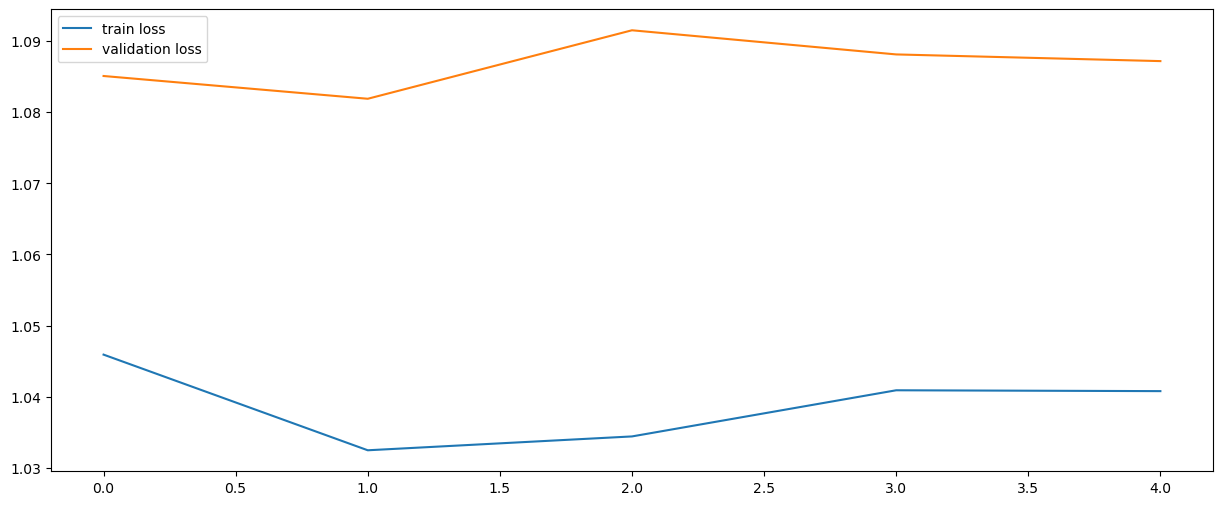

In [53]:
plt.figure(figsize=(15,6))
plt.plot(train_losses, label = 'train loss')
plt.plot(val_losses, label = 'validation loss')
plt.legend()

In [41]:
for name, param in model.named_parameters():
    if param.requires_grad and param.grad is None:
        print(f"{name} has no grad!")

# Model Testing

In [37]:
model = torch.load('best_val_model_pytorch')

n_correct = 0.
n_total = 0.

for inputs, targets in test_loader:
    # Move to MPS
    inputs, targets = inputs.to(device, dtype=torch.float), targets.to(device, dtype=torch.int64)

    # Get prediction
    # torch.max returns both max and argmax
    _, predictions = torch.max(outputs, 1)

    # update counts
    n_correct += (predictions == targets).sum().item()
    n_total += targets.shape[0]

test_acc = n_correct/n_total
print(f"Test acc: {test_acc:.4f}")

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL __main__.deeplob was not an allowed global by default. Please use `torch.serialization.add_safe_globals([deeplob])` or the `torch.serialization.safe_globals([deeplob])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn more about types accepted by default with weights_only ht

In [ ]:
all_targets = []
all_predictions = []


for inputs, targets in test_loader:
    # Move to MPS
    inputs, targets = inputs.to(device, dtype=torch.float), targets.to(device, dtype=torch.int64)

    # Get prediction
    # torch.max returns both max and argmax
    _, predictions = torch.max(outputs, 1)

    all_targets.append(targets.cpu().numpy())
    all_predictions.append(predictions.cpu().numpy())

all_targets = np.concatenate(all_targets)
all_predictions = np.concatenate(all_predictions)
